# ARIES and SEDEx on a synthetic 1DTE slice

This notebook runs the procedures of *From Arbitrage Removal to Density Extraction: A Model-Free Framework for Short-Dated Options* (Wizman, Turinici and Merran, arXiv:2605.22792) on the synthetic slice in `examples/data`.

**The data are synthetic.** They were generated from a parametric model with exchange-like conventions (strike lattice, ticks, spreads, sizes) for a fictitious index. They are not market data.

In [1]:
import json
import logging
import sys
from pathlib import Path

try:
    import aries_sedex
except ImportError:  # package not installed: use the source tree
    sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aries_sedex import OptionArbitrageModel, load_quotes, plotting

logging.basicConfig(level=logging.WARNING)
%matplotlib inline

## 1. Data

One row per listed option: strike, option type, bid, ask and the sizes at the bid and at the ask, in index points. The spot and the maturity are stored in the accompanying JSON file.

In [2]:
DATA = Path("data")
meta = json.loads((DATA / "synthetic_1dte.json").read_text())
quotes = load_quotes(DATA / "synthetic_1dte.csv")
spot, maturity = meta["spot"], meta["maturity_years"]
print(f"spot = {spot}, maturity = {maturity:.6f} years ({meta['maturity_days']} day)")
print(quotes.groupby("option_type").size().rename("quotes").to_string())
quotes.head()

spot = 5187.36, maturity = 0.002740 years (1 day)
option_type
C    112
P    115


,strike,option_type,bid,ask,bid_size,ask_size
0,4550.0,C,635.8,640.3,8.0,15.0
1,4575.0,C,610.3,614.8,28.0,37.0
2,4600.0,C,585.9,590.4,35.0,33.0
3,4625.0,C,560.6,565.1,17.0,46.0
4,4650.0,C,535.3,539.8,25.0,16.0


## 2. Interest rate and dividend yield

`calibrate_forward` estimates r and q by weighted least squares on put-call parity. At this maturity the forward is well determined but r and q taken separately are not: the data were generated with r = 4.25 % and q = 1.35 %. Use `model.set_rates(r, q)` to supply other values (section 6).

In [3]:
model = OptionArbitrageModel(quotes, spot=spot, maturity=maturity, strike_lattice=meta["strike_lattice"])
r, q = model.calibrate_forward()
print(f"{model.rates.n_strikes} strikes quoted for both calls and puts")
print(f"r = {r:.4%}, q = {q:.4%}, forward = {model.forward * spot:.3f}")

109 strikes quoted for both calls and puts
r = 5.0361%, q = 1.9794%, forward = 5187.794


## 3. Out-of-the-money quotes as calls

Puts below the forward are converted into calls by put-call parity; calls at or above the forward are kept. The semi-static conditions on vertical and butterfly spreads (which ignore the sizes) flag many combinations before ARIES.

In [4]:
call_quotes = model.build_call_quotes()
print(f"{len(call_quotes)} strikes: {(call_quotes.source == 'put').sum()} converted puts, {(call_quotes.source == 'call').sum()} calls")
print("violations before ARIES:", model.cousot_check("raw").summary())

118 strikes: 73 converted puts, 45 calls
violations before ARIES: {'intrinsic': 0, 'vertical': 43, 'butterfly': 780}


## 4. ARIES

ARIES removes one quote per iteration, the saturated quote with the smallest size in an arbitrage portfolio. `strong` marks a positive optimal value (strong arbitrage); `standard` marks a zero optimal value with a zero-cost portfolio whose payoff is nonnegative and positive in some state.

In [5]:
aries_result = model.detect_arbitrage()
removed = model.removed_quotes()
print(f"{len(removed)} quotes removed, {len(aries_result.quotes)} strikes kept")
print("violations after ARIES:", model.cousot_check("cleaned").summary())
removed[["iteration", "kind", "strike_points", "option_type", "side", "price", "size"]].rename(columns={"strike_points": "strike"})

6 quotes removed, 112 strikes kept
violations after ARIES: {'intrinsic': 0, 'vertical': 0, 'butterfly': 0}


,iteration,kind,strike,option_type,side,price,size
0,1,strong,5285.0,C,bid,0.20,2.0
1,2,strong,5020.0,P,bid,0.65,3.0
2,3,strong,4890.0,P,bid,0.35,4.0
3,4,standard,5450.0,C,bid,0.10,7.0
4,5,standard,5390.0,C,bid,0.10,5.0
5,6,standard,5335.0,C,bid,0.10,6.0


## 5. SEDEx

The grid contains every strike; its mesh is a divisor of the 5-point strike lattice close to `sigma_ATM * sqrt(2 pi T) * delta`. The solution is accepted only if its masses are nonnegative, sum to one, have the forward as mean and price every kept quote inside its bid-ask interval (to 0.01 tick). This step takes about half a minute.

In [6]:
res = model.extract_density()
info = res.solve_info
print(f"grid: {len(res.grid)} points, step {res.step * spot:.4f} index points (strike lattice / {res.refinement})")
print(f"sigma_ATM = {res.sigma_atm:.4f}, lambda_1 = {res.lambda1:g}, lambda_2 = {res.lambda2:.3e}")
print(f"solver: {info['status_final']}, retry: {info['retried']}, {info['solve_time_s']:.1f} s")
print(f"checks: min mass {info['min_mass']:.1e}, mass error {info['mass_error']:.1e}, "
      f"mean error {info['mean_error']:.1e}, max bid-ask violation {info['max_bidask_violation_ticks']:.1e} ticks")
pd.Series(res.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]) * spot,
          index=["1%", "5%", "25%", "50%", "75%", "95%", "99%"], name="quantiles of S_T").round(1)

grid: 4663 points, step 0.4167 index points (strike lattice / 12)
sigma_ATM = 0.1308, lambda_1 = 1, lambda_2 = 4.711e-06
solver: optimal, retry: False, 40.8 s
checks: min mass 1.9e-08, mass error 6.5e-09, mean error 6.5e-09, max bid-ask violation 1.4e-04 ticks


1%     5062.9
5%     5132.1
25%    5166.7
50%    5189.6
75%    5212.1
95%    5243.8
99%    5266.2
Name: quantiles of S_T, dtype: float64

### Density

The window is centered on the forward; its half-width is the larger distance from the forward to the 1 % and 99 % quantiles, plus 10 %. Use `xlim=(a, b)` to choose another window.

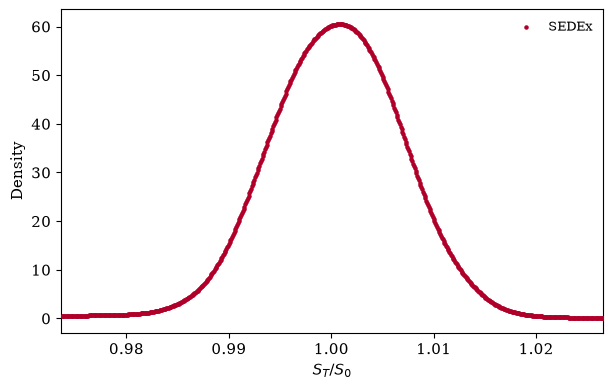

In [7]:
plotting.plot_density(model);

### Implied volatility smile

Bid and ask implied volatilities of the quotes kept by ARIES, and the SEDEx smile evaluated at the grid points (drawn as points). The smile extends beyond the quoted strikes (lighter points): by 10 % of the quoted range on the left and 25 % on the right, where the strikes are sparse. The density prices these strikes too; use `extrapolation=(left, right)` to change the extension.

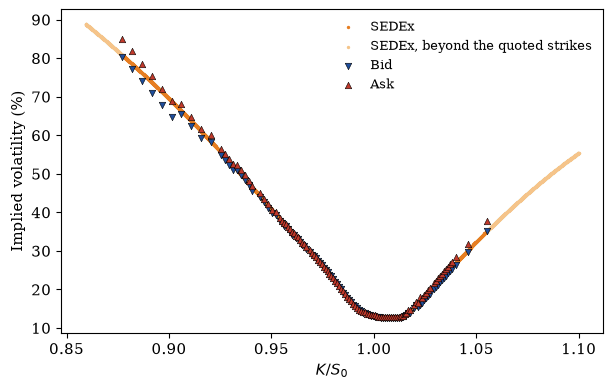

In [8]:
plotting.plot_smile(model);

### Bid-ask check

As in the paper: at each strike kept by ARIES, SEDEx implied volatility minus bid implied volatility where it is below the bid, minus ask implied volatility where it is above the ask. The values are of the order of the solver tolerance.

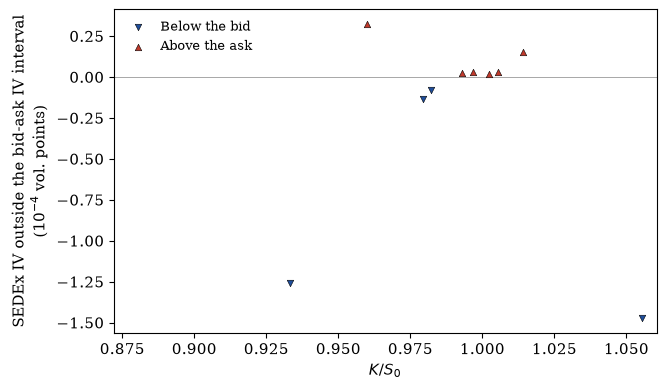

In [9]:
plotting.plot_iv_outside_bidask(model);

### Quotes removed by ARIES

All out-of-the-money quotes relative to the SEDEx price. The kept quotes bracket the SEDEx price; the removed bids lie above it.

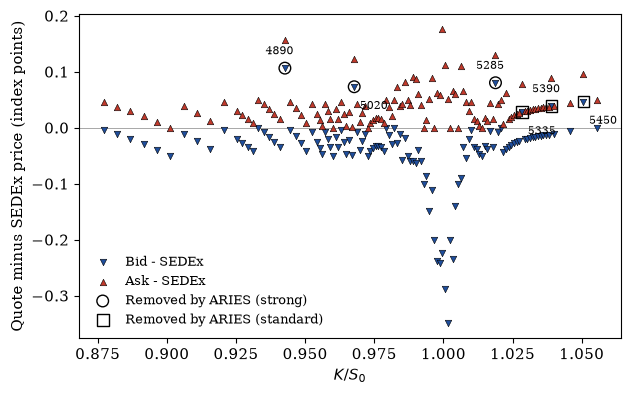

In [10]:
plotting.plot_aries(model);

## 6. Using your own r and q

ARIES and SEDEx take r and q as inputs. Here ARIES is run again with the rates used to generate the data: the same six quotes are removed.

In [11]:
check = OptionArbitrageModel(quotes, spot=spot, maturity=maturity)
check.set_rates(0.0425, 0.0135)
check.build_call_quotes()
check.detect_arbitrage()
check.removed_quotes()[["iteration", "kind", "strike_points", "side"]]

,iteration,kind,strike_points,side
0,1,strong,5285.0,bid
1,2,strong,5020.0,bid
2,3,strong,4890.0,bid
3,4,standard,5450.0,bid
4,5,standard,5390.0,bid
5,6,standard,5335.0,bid


## 7. Export

In [12]:
table = res.to_frame(in_index_points=True)   # state, mass, density (per index point)
table.head()

,state,mass,density
0,4041.250000,1.047133e-07,2.513120e-07
1,4041.666667,1.048194e-07,2.515665e-07
2,4042.083333,1.049289e-07,2.518293e-07
3,4042.500000,1.050386e-07,2.520927e-07
4,4042.916667,1.051485e-07,2.523564e-07
